# 🎙️ Podcast-Discussion: Multi-Workspace, Agenten-Workflow, Lastverteilung & Test-Roadmap

Dieses Notebook erzeugt eine **zweistimmige Podcast-Diskussion** (Hosts: **Alex** & **Mira**) rund um das gesamte `git-labor` / SimRacer-Ökosystem – erstellt mit dem **Google GenAI SDK (`google-genai`)**, der **Interactions API (`client.interactions.create`)**, **Gemini 3.8 Flash (`gemini-3.8-flash`)**, dem **Antigravity Managed Agent (`antigravity-preview-09-2026`)** und **Gemini Multi-Speaker TTS (`gemini-3.8-flash-tts`)**.

### Inhalte der Episode
1. **Multi-Root Workspace (`git-labor.code-workspace`):** Wie die 5 Repositories (`Git-Labor`, `Local-Cyborg`, `AC-CM-CSP-Sandbox`, `Assetto-Corsa-Content`, `StrikerPi-Hub`) zusammenspielen.
2. **Agenten-Workflow (6 Rollen):** Zusammenspiel von `@general` (`General Cyborg` / `General Sim`), `@rig`, `@light`, `@dark`, `@sarah` und `@rick` über `inbox/` → `outbox/`, Freigabe-Gates und Host-Lokal vs. SSH `-ClientMode`.
3. **Lastverteilung auf den 4 physischen Geräten:** CPU-, GPU-, RAM- und Netzwerk-Aufteilung zwischen `VanstrikeCyborg`, `SimRacer` (inkl. `ac-win11-sandbox`), `Archibald` (Pitwall) und `StrikerPi` (24/7 Hub) im Zeitmultiplex (`ENGINEERING`, `LIVE_RACE`, `PITBOX_SETUP`).
4. **Offene Tests & Erweiterungen:** Verifizierte Lücken aus Testberichten und Skripten sowie konkrete Ausbau-Prioritäten.

## 1. Setup & Live-Inspektion des Multi-Root-Workspaces
Wir prüfen die Python-Umgebung (`google-genai`, `matplotlib`), den `GEMINI_API_KEY`-Status und lesen die reale Multi-Root-Konfiguration aus `git-labor.code-workspace` sowie die definierten Custom Agents ein.

In [11]:
import json
import os
import sys
from pathlib import Path

from google import genai
import matplotlib.pyplot as plt

if sys.platform == "win32":
    try:
        import winreg

        with winreg.OpenKey(winreg.HKEY_CURRENT_USER, "Environment") as reg_key:
            user_api_key, _ = winreg.QueryValueEx(reg_key, "GEMINI_API_KEY")
        if user_api_key and not str(user_api_key).startswith("<"):
            os.environ["GEMINI_API_KEY"] = str(user_api_key).strip()
    except OSError:
        pass

NOTEBOOK_DIR = Path.cwd()
GIT_LABOR_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebook-agent-environments" else Path(r"c:\Users\strik\git-labor")
WORKSPACE_FILE = GIT_LABOR_ROOT / "git-labor.code-workspace"
AGENTS_DIR = GIT_LABOR_ROOT / ".github" / "agents"

raw_workspace = json.loads(WORKSPACE_FILE.read_text(encoding="utf-8"))
folders = raw_workspace.get("folders", [])
agent_files = sorted(p.name for p in AGENTS_DIR.glob("*.agent.md"))
doku_files = sorted(str(p.relative_to(GIT_LABOR_ROOT / "Doku")) for p in (GIT_LABOR_ROOT / "Doku").rglob("*.md"))

api_key_present = bool(os.getenv("GEMINI_API_KEY"))

print(f"Python Runtime      : {sys.version.split()[0]}")
print(f"google-genai SDK    : geladen ({genai.__name__})")
print(f"GEMINI_API_KEY      : {'GESETZT (Online-API aktiv)' if api_key_present else 'NICHT GESETZT (Offline-/Preview-Modus aktiv)'}")
print(f"Workspace-Ordner    : {len(folders)}")
for idx, folder in enumerate(folders, start=1):
    print(f"  {idx}. {folder['name']} -> {folder['path']}")
print(f"Custom Agents       : {', '.join(agent_files)}")
print(f"Doku-Dateien (Doku/): {len(doku_files)} Markdown-Dokumente")

Python Runtime      : 3.14.7
google-genai SDK    : geladen (google.genai)
GEMINI_API_KEY      : GESETZT (Online-API aktiv)
Workspace-Ordner    : 5
  1. 1_Git-Labor (mestuermer-svg/first) -> .
  2. 2_Local-Cyborg (mestuermer-svg/local_Cyborg) -> ../../../local_Cyborg
  3. 3_AC-CM-CSP-Sandbox (mestuermer-svg/ac-cm-csp-sandbox) -> ../ac-cm-csp-sandbox
  4. 4_Assetto-Corsa-Content (mestuermer-svg/assetto-corsa-content) -> ../assetto-corsa-content
  5. 5_StrikerPi-Hub (strikerpi/simrig.git) -> ../strikerpi-hub
Custom Agents       : dark.agent.md, general.agent.md, light.agent.md, rick.agent.md, rig.agent.md, sarah.agent.md
Doku-Dateien (Doku/): 27 Markdown-Dokumente


## 2. Strukturierte Wissensbasis: Workspace, Agenten, 4 Geräte & offene Testpunkte
Diese Zelle bündelt alle verifizierten Fakten aus dem Workspace (`git-labor.code-workspace`, `.github/agents/`, `Doku/05_Agents/`, `strikerpi-hub` und Testberichten) als maschinenlesbares Kontextmodell für **@gemini**, **@antigravity** und das **Podcast-Skript**.

In [2]:
from dataclasses import dataclass, asdict


@dataclass(frozen=True)
class DeviceNode:
    name: str
    ip: str
    hardware: str
    os_role: str
    agents: list[str]
    cpu_load_engineering: int
    cpu_load_live_race: int
    ram_load_pct: int
    gpu_load_live_race: int
    primary_tasks: str


@dataclass(frozen=True)
class GapItem:
    id: str
    area: str
    severity: str
    summary: str
    next_action: str


WORKSPACE_REPOS = [
    ("1_Git-Labor", "Zentrale Doku (Doku/01..05), Labs, Agent-Terminals.ps1, Notebook-Umgebung (uv + google-genai)"),
    ("2_Local-Cyborg", "Lokale Treiber/BIOS/VR-Setup auf VanstrikeCyborg sowie Gemini/, Opencode/, Tool-Box/"),
    ("3_AC-CM-CSP-Sandbox", "AC-Setups (01..10_*), Content Manager & CSP-Konfigurationen als Sandbox-Basis"),
    ("4_Assetto-Corsa-Content", "ac-sandbox/, Docker Compose, Focus-Watchdog, Invoke-RigAgent/DarkAgent & Agent-Worker"),
    ("5_StrikerPi-Hub", "24/7 Raspberry Pi 4 Services: @rick Worker, Telemetry-Relay (:8080), Mosquitto MQTT & Bare-Git"),
]

AGENT_ROLES = [
    {"agent": "@general (General Cyborg / General Sim)", "ebene": "Ebene 1 – Leitstand", "host": "VanstrikeCyborg", "mode": "VS Code Chat + SSH -ClientMode"},
    {"agent": "@rig (Rig Agent)", "ebene": "Ebene 2 – SimRacer Host", "host": "SimRacer", "mode": "Host-Lokal (Hardware, SteamVR, RTX 5070 Ti, NVIDIA MCP :13508)"},
    {"agent": "@light (SimRacer Light)", "ebene": "Ebene 2 – Docker-Host", "host": "SimRacer", "mode": "Host-Lokal (Docker Desktop, ac-win11-sandbox, race.ini, Backups)"},
    {"agent": "@dark (Sandbox Dark)", "ebene": "Ebene 3 – In-Container", "host": "ac-win11-sandbox (Win 11 VM)", "mode": "Isolierter Guest-Worker (CM-Starts, Setup-Validierung, UI-Tests)"},
    {"agent": "@sarah (Sarah Coach)", "ebene": "Support – Pitwall", "host": "Archibald (IdeaPad 5)", "mode": "systemd (UDP :9996, edge-tts Voice, Pitfiles, 2-Säulen-FFmpeg-Schnitt)"},
    {"agent": "@rick (Rick Agent)", "ebene": "24/7 Infrastructure Hub", "host": "StrikerPi (RPi 4)", "mode": "systemd (inbox/outbox, MQTT :1883, Relay :8080, Bare-Git, 409-Lock)"},
]

DEVICES = [
    DeviceNode(
        name="VanstrikeCyborg (Laptop)",
        ip="192.168.178.172",
        hardware="Core 7 240H | RTX 5060 8 GB | 16 GB DDR5",
        os_role="Windows 11 – Leitstand & IDE",
        agents=["@general (General Cyborg / General Sim)"],
        cpu_load_engineering=45,
        cpu_load_live_race=20,
        ram_load_pct=55,
        gpu_load_live_race=10,
        primary_tasks="VS Code Multi-Root, KI-Orchestrierung, SSH -ClientMode, Notebooks, Git",
    ),
    DeviceNode(
        name="SimRacer (Workstation)",
        ip="192.168.178.68",
        hardware="Ryzen 9 3900X 12C/24T | RTX 5070 Ti 16 GB | 32 GB DDR4",
        os_role="Windows 11 Pro – Race Rig + Docker VM (Zeitmultiplex)",
        agents=["@rig", "@light", "@dark (in ac-win11-sandbox: 8 vCPU / 12 GB RAM)"],
        cpu_load_engineering=75,
        cpu_load_live_race=65,
        ram_load_pct=78,
        gpu_load_live_race=95,
        primary_tasks="LIVE_RACE: 120 Hz VR + AC (Sandbox pausiert!) | ENGINEERING: Docker VM + Tests",
    ),
    DeviceNode(
        name="Archibald (Pitwall IdeaPad 5)",
        ip="192.168.178.98",
        hardware="IdeaPad 5 (WoWLAN s2idle)",
        os_role="Arch Linux / Omarchy + Hyprland",
        agents=["@sarah (Sarah Coach)"],
        cpu_load_engineering=30,
        cpu_load_live_race=68,
        ram_load_pct=50,
        gpu_load_live_race=25,
        primary_tasks="Live-Pitwall (:8080), UDP :9996, edge-tts Voice, 100% FFmpeg-Videoschnitt",
    ),
    DeviceNode(
        name="StrikerPi (24/7 Hub)",
        ip="192.168.178.86",
        hardware="Raspberry Pi 4 (~5 W Always-On)",
        os_role="Arch Linux ARM",
        agents=["@rick (Rick Agent)"],
        cpu_load_engineering=22,
        cpu_load_live_race=32,
        ram_load_pct=42,
        gpu_load_live_race=0,
        primary_tasks="Telemetry-Relay (:50005->:9996), FastAPI/WS (:8080), Mosquitto (:1883), Bare-Git, 409-Lock",
    ),
]

TEST_AND_EXPANSION_GAPS = [
    GapItem("G-01", "Logging Race Condition", "Hoch", "Send-DarkAgentTask.ps1 / worker.ps1: Tasks < 2s verschwinden vor dem Polling; requester/reply_to fehlen.", "Atomares Audit-Logging direkt beim Worker-Ack + requester/reply_to-Metadaten ergänzen."),
    GapItem("G-02", "Rig -> Light Handoff", "Hoch", "start_rig_terminal.ps1 setzt approved_by='GeneralAgent_Laptop' nicht, löst redundantes Gate (15s Pending) aus.", "Explizite Freigabe-Felder im Handoff-Payload setzen und E2E-Handshake verifizieren."),
    GapItem("G-03", "Sarah Inbox & Logging", "Hoch", "start_sarah_terminal.ps1 pollt telemetry\\inbox\\ noch nicht (2 offene Alt-Tasks) und schreibt kein .log + OSC-8-Link.", "Inbox-Polling nachrüsten und mit start_sarah_terminal.sh auf Archibald abgleichen."),
    GapItem("G-04", "Dark Timer & File-Lock", "Mittel", "start_dark_terminal.ps1 (Z.397 fehlendes $stopwatch) -> 0s; runner.ps1 (Z.78) paralleler Lock auf dark-status.json.", "Stopwatch sauber initialisieren und Status-Updates atomar/mit Retry schreiben."),
    GapItem("G-05", "Host-Lokal vs. SSH -ClientMode", "Mittel", "Alle 6 Terminals aus Agent-Terminals.ps1 wurden noch nicht geschlossen als E2E-Matrix getestet.", "Volltest aller 6 SSH-Terminals + ExecutionTimeLimit=0 / systemd-Restart-Resilienz."),
    GapItem("G-06", "StrikerPi 409-Lock & MJPEG", "Mittel", "Sandbox-API (/api/sandbox/* 409-Lock) & sim_stream_server.py (:8090) unter echter 120-Hz-VR-Last prüfen.", "Lasttest während aktiver VR-Session + Latenzmessung über StrikerPi-Relay."),
    GapItem("G-07", "Archibald WoWLAN Edge-Cases", "Niedrig", "wake_archibald.ps1 / sleep_archibald.ps1 brauchen Retry- und Timeout-Tests bei instabilem WLAN.", "Robuste Retry-Schleife und Healthcheck gegen :9996/:8317 nach Wake-up."),
    GapItem("G-08", "Port 8317 & GEMINI_API_KEY", "Erweiterung", "127.0.0.1:8317 liefert lokal Antigravity-HTML statt CLIProxyAPI JSON; GEMINI_API_KEY noch nicht gesetzt.", "Saubere Port-Trennung (Proxy vs. IDE) & API-Key via Env/Secret für Live-Audio-Synthese."),
]

CONTEXT_JSON = json.dumps(
    {
        "workspace_repos": [{"name": n, "role": r} for n, r in WORKSPACE_REPOS],
        "agent_roles": AGENT_ROLES,
        "devices": [asdict(d) for d in DEVICES],
        "test_and_expansion_gaps": [asdict(g) for g in TEST_AND_EXPANSION_GAPS],
    },
    ensure_ascii=False,
    indent=2,
)

print(f"Kontext geladen: {len(WORKSPACE_REPOS)} Repos | {len(AGENT_ROLES)} Agenten | {len(DEVICES)} Geräte | {len(TEST_AND_EXPANSION_GAPS)} Test-/Ausbaupunkte")
print(f"JSON-Kontextgröße: {len(CONTEXT_JSON):,} Zeichen")

Kontext geladen: 5 Repos | 6 Agenten | 4 Geräte | 8 Test-/Ausbaupunkte
JSON-Kontextgröße: 6,772 Zeichen


## 3. Lastverteilung auf den 4 Geräten (Zeitmultiplex: `ENGINEERING` vs. `LIVE_RACE`)
Die Grafik zeigt, wie Rechen-, Speicher- und Grafiklast über die vier physischen Knoten (`VanstrikeCyborg`, `SimRacer`, `Archibald`, `StrikerPi`) verteilt sind — inklusive des **Zeitmultiplex-Prinzips** auf dem `SimRacer` (pausierte Docker-Sandbox im `LIVE_RACE`-Betrieb) und der kompletten Auslagerung des FFmpeg-Videoschnitts auf `Archibald`.

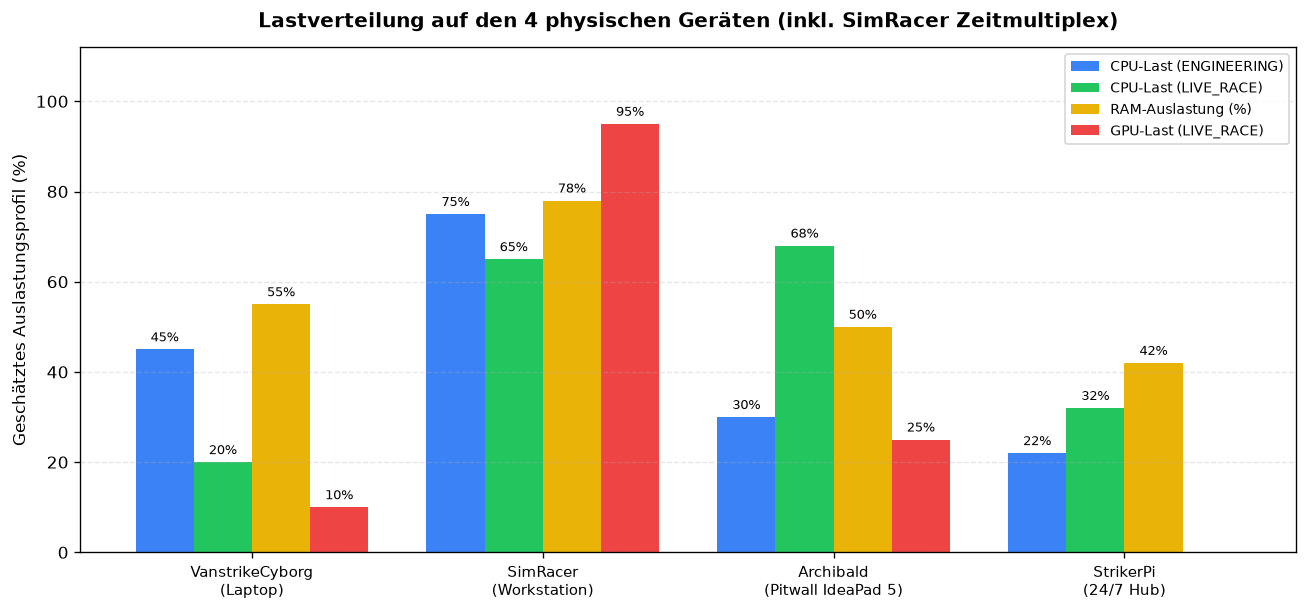

Rollen-Zusammenfassung pro Gerät:
- VanstrikeCyborg (Laptop) [192.168.178.172]: @general (General Cyborg / General Sim) -> VS Code Multi-Root, KI-Orchestrierung, SSH -ClientMode, Notebooks, Git
- SimRacer (Workstation) [192.168.178.68]: @rig, @light, @dark (in ac-win11-sandbox: 8 vCPU / 12 GB RAM) -> LIVE_RACE: 120 Hz VR + AC (Sandbox pausiert!) | ENGINEERING: Docker VM + Tests
- Archibald (Pitwall IdeaPad 5) [192.168.178.98]: @sarah (Sarah Coach) -> Live-Pitwall (:8080), UDP :9996, edge-tts Voice, 100% FFmpeg-Videoschnitt
- StrikerPi (24/7 Hub) [192.168.178.86]: @rick (Rick Agent) -> Telemetry-Relay (:50005->:9996), FastAPI/WS (:8080), Mosquitto (:1883), Bare-Git, 409-Lock


In [3]:
import numpy as np

labels = [d.name.replace(" (", "\n(") for d in DEVICES]
cpu_eng = [d.cpu_load_engineering for d in DEVICES]
cpu_race = [d.cpu_load_live_race for d in DEVICES]
ram_pct = [d.ram_load_pct for d in DEVICES]
gpu_race = [d.gpu_load_live_race for d in DEVICES]

x = np.arange(len(labels))
width = 0.2

fig, ax = plt.subplots(figsize=(11, 5.2), dpi=120)
bars1 = ax.bar(x - 1.5 * width, cpu_eng, width, label="CPU-Last (ENGINEERING)", color="#3b82f6")
bars2 = ax.bar(x - 0.5 * width, cpu_race, width, label="CPU-Last (LIVE_RACE)", color="#22c55e")
bars3 = ax.bar(x + 0.5 * width, ram_pct, width, label="RAM-Auslastung (%)", color="#eab308")
bars4 = ax.bar(x + 1.5 * width, gpu_race, width, label="GPU-Last (LIVE_RACE)", color="#ef4444")

ax.set_title("Lastverteilung auf den 4 physischen Geräten (inkl. SimRacer Zeitmultiplex)", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Geschätztes Auslastungsprofil (%)")
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylim(0, 112)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(loc="upper right", fontsize=8.5, frameon=True)

for bar_group in (bars1, bars2, bars3, bars4):
    for bar in bar_group:
        h = bar.get_height()
        if h > 0:
            ax.annotate(f"{h}%", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3),
                        textcoords="offset points", ha="center", va="bottom", fontsize=7.5)

plt.tight_layout()
plt.show()

print("Rollen-Zusammenfassung pro Gerät:")
for d in DEVICES:
    print(f"- {d.name} [{d.ip}]: {', '.join(d.agents)} -> {d.primary_tasks}")

## 4. Podcast-Diskussion mit `@antigravity` & `@gemini` (Interactions API)
Wir definieren ein striktes Pydantic-Schema (`PodcastEpisode`) für eine zweistimmige deutsche Podcast-Episode zwischen **Alex** (Systemarchitekt & Host) und **Mira** (DevOps-, Telemetrie- & Testing-Ingenieurin):
- **Mit `GEMINI_API_KEY`:**
  1. Optionales Architektur-Briefing über den Managed Agent **`antigravity-preview-09-2026`** (`client.interactions.create(agent="antigravity-preview-09-2026", environment="remote", agent_config={"type": "antigravity", "model": "gemini-4-argon"})`).
  2. Strukturierte Skript-Synthese über **`gemini-3.8-flash`** (`response_format={"type": "text", "mime_type": "application/json", "schema": ...}`).
- **Ohne `GEMINI_API_KEY` (Offline-Fallback):** Es wird die kuratierte, vollständig auf die realen Workspace-Fakten abgestimmte Podcast-Diskussion ausgegeben, sodass das Notebook jederzeit ohne Fehler durchläuft.

In [12]:
from typing import Literal
from IPython.display import Markdown, display
from pydantic import BaseModel, Field


class PodcastTurn(BaseModel):
    speaker: Literal["Alex", "Mira"] = Field(description="Sprechername für die Multi-Speaker-TTS-Pipeline")
    style: str = Field(description="Regieanweisung für die Stimmführung (z. B. 'neugierig und klar')")
    topic: str = Field(description="Themenblock innerhalb der Episode")
    text: str = Field(description="Gesprochener deutscher Podcast-Beitrag")


class PodcastEpisode(BaseModel):
    title: str
    summary: str
    turns: list[PodcastTurn]


CURATED_EPISODE = PodcastEpisode(
    title="Vier Geräte, sechs Agenten, ein Ziel: Architektur, Lastverteilung & Test-Roadmap im git-labor",
    summary="Alex und Mira analysieren den 5-Repo-Multi-Root-Workspace, den file-basierten 6-Agenten-Workflow, das Zeitmultiplex auf 4 physischen Geräten sowie die wichtigsten offenen Test- und Ausbaupunkte.",
    turns=[
        PodcastTurn(
            speaker="Alex",
            style="energetisch und einladend",
            topic="Intro & Multi-Root-Workspace",
            text=(
                "Willkommen zu einer neuen Folge unseres Architektur-Deep-Dives! Heute schauen wir uns ein Setup an, "
                "das auf den ersten Blick wie ein klassischer SimRacing-Rig wirkt, dahinter aber ein ziemlich durchdachtes "
                "verteiltes System aus fünf Repositories in einer Multi-Root-VS-Code-Umgebung versteckt: git-labor."
            ),
        ),
        PodcastTurn(
            speaker="Mira",
            style="analytisch und begeistert",
            topic="Die 5 Repositories",
            text=(
                "Genau, Alex. In git-labor.code-workspace laufen fünf ganz unterschiedliche Welten sauber getrennt zusammen: "
                "1_Git-Labor hält die Doku, die Agenten-Launcher und diese Python-Notebook-Umgebung. "
                "2_Local-Cyborg enthält die lokalen Treiber-, BIOS- und KI-Tools des Laptops. "
                "3_AC-CM-CSP-Sandbox ist das Konfigurations- und Setup-Fundament für Assetto Corsa und Content Manager. "
                "4_Assetto-Corsa-Content orchestriert die Docker-Sandbox auf dem SimRacer, und 5_StrikerPi-Hub bündelt "
                "alles, was rund um die Uhr auf dem Raspberry Pi 4 läuft."
            ),
        ),
        PodcastTurn(
            speaker="Alex",
            style="fokussiert und strukturiert",
            topic="6-Agenten-Workflow",
            text=(
                "Spannend wird es beim Agenten-Workflow. Es gibt sechs klar abgegrenzte Rollen über drei Ebenen plus Pitwall und Hub: "
                "Auf Ebene 1 sitzt @general auf dem Laptop VanstrikeCyborg als Leitstand. Von hier aus gehen Tasks per "
                "Send-SimAgentTask oder SSH im ClientMode raus, ohne dass der Laptop eigene Worker-Dauerschleifen startet. "
                "Auf Ebene 2 teilen sich @rig für Hardware, SteamVR und RTX 5070 Ti sowie @light für Docker Desktop, "
                "race.ini und Backups den SimRacer-Host."
            ),
        ),
        PodcastTurn(
            speaker="Mira",
            style="präzise und praxisnah",
            topic="Sandbox, Pre-Flight & Approval-Gate",
            text=(
                "Und auf Ebene 3 arbeitet @dark komplett isoliert in der Windows-11-Docker-VM ac-win11-sandbox. "
                "Ganz wichtig im Workflow sind zwei Sicherheitsnetze: Erstens der Pre-Flight-Check, damit kein Task blind "
                "in einen gestoppten Container läuft. Zweitens das Approval-Gate: Wenn @rig oder @light Änderungen vorschlagen, "
                "warten sie explizit auf das ok oder nein von @general. Die Kommunikation selbst läuft asynchron über "
                "inbox- und outbox-JSONs auf dem SMB-Share und wird parallel in die Kommunikationshistorie geschrieben."
            ),
        ),
        PodcastTurn(
            speaker="Alex",
            style="neugierig und dynamisch",
            topic="Lastverteilung auf den 4 Geräten",
            text=(
                "Kommen wir zur Hardware-Frage: Wie verteilt sich die Rechenlast auf die vier physischen Geräte, damit "
                "beim Fahren in 120-Hertz-VR nichts ruckelt?"
            ),
        ),
        PodcastTurn(
            speaker="Mira",
            style="fachkundig und klar",
            topic="Zeitmultiplex, Pitwall & 24/7 Hub",
            text=(
                "Das Stichwort lautet Zeitmultiplex plus konsequentes Offloading! "
                "Gerät 1, VanstrikeCyborg, trägt nur die IDE, Antigravity, Git, Notebooks und SSH-Client-Terminals – null lokale Docker-Last. "
                "Gerät 2, der SimRacer mit Ryzen 9 3900X, 32 GB RAM und RTX 5070 Ti, kennt zwei Modi: Im LIVE_RACE-Modus "
                "pausiert der Focus-Watchdog die 8-vCPU-Docker-Sandbox komplett auf null Prozent CPU. Nur ac_telemetry_sender.py "
                "nimmt unter 0,2 Prozent CPU für 50-Hertz-UDP. Erst im ENGINEERING-Modus bekommt die VM wieder ihre 8 vCPUs und 12 GB RAM. "
                "Gerät 3, das IdeaPad Archibald unter Omarchy Linux, übernimmt @sarah auf Port 9996, die edge-tts-Sprachausgabe "
                "und zu hundert Prozent den schweren FFmpeg-Videoschnitt. Und Gerät 4, der StrikerPi, hält bei rund fünf Watt "
                "24/7 das Telemetry-Relay auf Port 50005 zu 9996, FastAPI auf 8080, Mosquitto MQTT, das Bare-Git-Repo und die Sandbox-Sperre am Laufen."
            ),
        ),
        PodcastTurn(
            speaker="Alex",
            style="kritisch und konstruktiv",
            topic="Was noch sauber getestet werden muss",
            text=(
                "Das Fundament steht, aber ein paar Stellen brauchen noch echte Härtetests und Bugfixes, richtig? "
                "Welche Baustellen stehen in den Testberichten ganz oben?"
            ),
        ),
        PodcastTurn(
            speaker="Mira",
            style="sachlich und lösungsorientiert",
            topic="Offene Test- & Ausbaupunkte",
            text=(
                "Vier konkrete Punkte stechen sofort heraus: Erstens die Logging-Race-Condition bei Send-DarkAgentTask und worker.ps1 – "
                "schnelle Tasks unter zwei Sekunden verschwinden aus Inbox und Outbox, bevor das Polling sie protokolliert, und requester sowie reply_to fehlen. "
                "Zweitens der @rig-zu-@light-Handoff in start_rig_terminal.ps1: Weil approved_by nicht gesetzt wird, triggert aktuell ein überflüssiges 15-Sekunden-Pending-Gate. "
                "Drittens pollt start_sarah_terminal.ps1 die telemetry-Inbox noch nicht, schreibt kein sauberes Log mit OSC-8-Link und muss mit der Linux-Variante auf Archibald abgeglichen werden. "
                "Und viertens haben wir in start_dark_terminal.ps1 eine fehlende Stopwatch-Initialisierung sowie in runner.ps1 einen File-Lock-Konflikt auf dark-status.json."
            ),
        ),
        PodcastTurn(
            speaker="Alex",
            style="zusammenfassend und motivierend",
            topic="Erweiterungs-Roadmap & Outro",
            text=(
                "Dazu kommen die großen End-to-End-Tests für unsere jüngsten Erweiterungen: Alle sechs Terminals sauber im Modus "
                "Host-Lokal gegen SSH-ClientMode abnehmen, den 409-Live-Session-Lock der StrikerPi-Sandbox-API prüfen, "
                "den MJPEG-Stream auf Port 8090 unter echter 120-Hertz-VR-Last messen, WoWLAN-Timeouts auf Archibald abhärten "
                "und lokal Port 8317 samt GEMINI_API_KEY sauber trennen. Wenn diese Punkte abgehakt sind, läuft der Verbund komplett rund!"
            ),
        ),
    ],
)

RUN_ANTIGRAVITY_BRIEFING = False  # Bei gesetztem GEMINI_API_KEY auf True setzen für Remote-Agent-Briefing
USE_LIVE_GEMINI_SCRIPT = bool(os.getenv("GEMINI_API_KEY"))

antigravity_briefing_text = None
episode = CURATED_EPISODE
generation_source = "Kuratiertes Offline-Skript (verifizierte Workspace-Daten)"
live_api_error = None

if USE_LIVE_GEMINI_SCRIPT:
    client = genai.Client()
    try:
        if RUN_ANTIGRAVITY_BRIEFING:
            ag_interaction = client.interactions.create(
                agent="antigravity-preview-09-2026",
                input=(
                    "Erstelle eine kompakte deutsche Stichpunkt-Analyse (max. 6 Punkte) zu Risiken bei "
                    "Multi-Device-Agenten-Queues und Zeitmultiplex-Workloads basierend auf diesem JSON-Kontext:\n"
                    + CONTEXT_JSON
                ),
                environment="remote",
                agent_config={"type": "antigravity", "model": "gemini-4-argon"},
            )
            antigravity_briefing_text = ag_interaction.output_text

        prompt = (
            "Erstelle auf Basis der folgenden verifizierten Systemdaten eine spannende, präzise deutsche "
            "Podcast-Diskussion zwischen Alex (Systemarchitekt) und Mira (DevOps & Telemetry Engineer) mit 8 bis 10 Sprechwechseln.\n"
            "Pflichtinhalte:\n"
            "1. Multi-Root Workspace (5 Repos in git-labor.code-workspace).\n"
            "2. 6-Agenten-Workflow (@general, @rig, @light, @dark, @sarah, @rick) inkl. inbox/outbox, Pre-Flight & Approval-Gate.\n"
            "3. Lastverteilung auf den 4 Geräten (VanstrikeCyborg, SimRacer Zeitmultiplex LIVE_RACE vs. ENGINEERING, Archibald FFmpeg, StrikerPi 24/7).\n"
            "4. Konkrete Bereiche, die noch sauber getestet und erweitert werden müssen.\n\n"
            f"Systemdaten (JSON):\n{CONTEXT_JSON}"
        )
        if antigravity_briefing_text:
            prompt += f"\n\nZusätzliches Antigravity-Briefing:\n{antigravity_briefing_text}"

        script_interaction = client.interactions.create(
            model="gemini-3.8-flash",
            input=prompt,
            response_format={
                "type": "text",
                "mime_type": "application/json",
                "schema": PodcastEpisode.model_json_schema(),
            },
        )
        episode = PodcastEpisode.model_validate_json(script_interaction.output_text)
        generation_source = "Live generiert via gemini-3.8-flash (Interactions API)"
    except Exception as exc:
        live_api_error = str(exc)
        generation_source = "Fallback auf kuratiertes Skript (Live-API-Aufruf blockiert)"

md_lines = [
    f"### 🎧 {episode.title}",
    f"*Quelle:* `{generation_source}`  ",
    f"*Kurzfassung:* {episode.summary}\n",
]
if live_api_error:
    md_lines.append(f"> ⚠️ **Live-API-Hinweis:** `{live_api_error}`\n")
for i, turn in enumerate(episode.turns, start=1):
    badge = "🟦 **Alex**" if turn.speaker == "Alex" else "🟪 **Mira**"
    md_lines.append(f"**{i}. {badge}** *({turn.topic} | Ton: {turn.style})*  \n{turn.text}\n")

display(Markdown("\n".join(md_lines)))

### 🎧 Vier Geräte, sechs Agenten, ein Ziel: Architektur, Lastverteilung & Test-Roadmap im git-labor
*Quelle:* `Fallback auf kuratiertes Skript (Live-API-Aufruf blockiert)`  
*Kurzfassung:* Alex und Mira analysieren den 5-Repo-Multi-Root-Workspace, den file-basierten 6-Agenten-Workflow, das Zeitmultiplex auf 4 physischen Geräten sowie die wichtigsten offenen Test- und Ausbaupunkte.

> ⚠️ **Live-API-Hinweis:** `Error code: 402 - [{'error': {'code': 402, 'message': 'Your prepayment credits are depleted. Please go to AI Studio at https://ai.studio/projects to manage your project and billing. Learn more at https://ai.google.dev/gemini-api/docs/billing#prepay. ', 'status': 'RESOURCE_EXHAUSTED'}}]`

**1. 🟦 **Alex**** *(Intro & Multi-Root-Workspace | Ton: energetisch und einladend)*  
Willkommen zu einer neuen Folge unseres Architektur-Deep-Dives! Heute schauen wir uns ein Setup an, das auf den ersten Blick wie ein klassischer SimRacing-Rig wirkt, dahinter aber ein ziemlich durchdachtes verteiltes System aus fünf Repositories in einer Multi-Root-VS-Code-Umgebung versteckt: git-labor.

**2. 🟪 **Mira**** *(Die 5 Repositories | Ton: analytisch und begeistert)*  
Genau, Alex. In git-labor.code-workspace laufen fünf ganz unterschiedliche Welten sauber getrennt zusammen: 1_Git-Labor hält die Doku, die Agenten-Launcher und diese Python-Notebook-Umgebung. 2_Local-Cyborg enthält die lokalen Treiber-, BIOS- und KI-Tools des Laptops. 3_AC-CM-CSP-Sandbox ist das Konfigurations- und Setup-Fundament für Assetto Corsa und Content Manager. 4_Assetto-Corsa-Content orchestriert die Docker-Sandbox auf dem SimRacer, und 5_StrikerPi-Hub bündelt alles, was rund um die Uhr auf dem Raspberry Pi 4 läuft.

**3. 🟦 **Alex**** *(6-Agenten-Workflow | Ton: fokussiert und strukturiert)*  
Spannend wird es beim Agenten-Workflow. Es gibt sechs klar abgegrenzte Rollen über drei Ebenen plus Pitwall und Hub: Auf Ebene 1 sitzt @general auf dem Laptop VanstrikeCyborg als Leitstand. Von hier aus gehen Tasks per Send-SimAgentTask oder SSH im ClientMode raus, ohne dass der Laptop eigene Worker-Dauerschleifen startet. Auf Ebene 2 teilen sich @rig für Hardware, SteamVR und RTX 5070 Ti sowie @light für Docker Desktop, race.ini und Backups den SimRacer-Host.

**4. 🟪 **Mira**** *(Sandbox, Pre-Flight & Approval-Gate | Ton: präzise und praxisnah)*  
Und auf Ebene 3 arbeitet @dark komplett isoliert in der Windows-11-Docker-VM ac-win11-sandbox. Ganz wichtig im Workflow sind zwei Sicherheitsnetze: Erstens der Pre-Flight-Check, damit kein Task blind in einen gestoppten Container läuft. Zweitens das Approval-Gate: Wenn @rig oder @light Änderungen vorschlagen, warten sie explizit auf das ok oder nein von @general. Die Kommunikation selbst läuft asynchron über inbox- und outbox-JSONs auf dem SMB-Share und wird parallel in die Kommunikationshistorie geschrieben.

**5. 🟦 **Alex**** *(Lastverteilung auf den 4 Geräten | Ton: neugierig und dynamisch)*  
Kommen wir zur Hardware-Frage: Wie verteilt sich die Rechenlast auf die vier physischen Geräte, damit beim Fahren in 120-Hertz-VR nichts ruckelt?

**6. 🟪 **Mira**** *(Zeitmultiplex, Pitwall & 24/7 Hub | Ton: fachkundig und klar)*  
Das Stichwort lautet Zeitmultiplex plus konsequentes Offloading! Gerät 1, VanstrikeCyborg, trägt nur die IDE, Antigravity, Git, Notebooks und SSH-Client-Terminals – null lokale Docker-Last. Gerät 2, der SimRacer mit Ryzen 9 3900X, 32 GB RAM und RTX 5070 Ti, kennt zwei Modi: Im LIVE_RACE-Modus pausiert der Focus-Watchdog die 8-vCPU-Docker-Sandbox komplett auf null Prozent CPU. Nur ac_telemetry_sender.py nimmt unter 0,2 Prozent CPU für 50-Hertz-UDP. Erst im ENGINEERING-Modus bekommt die VM wieder ihre 8 vCPUs und 12 GB RAM. Gerät 3, das IdeaPad Archibald unter Omarchy Linux, übernimmt @sarah auf Port 9996, die edge-tts-Sprachausgabe und zu hundert Prozent den schweren FFmpeg-Videoschnitt. Und Gerät 4, der StrikerPi, hält bei rund fünf Watt 24/7 das Telemetry-Relay auf Port 50005 zu 9996, FastAPI auf 8080, Mosquitto MQTT, das Bare-Git-Repo und die Sandbox-Sperre am Laufen.

**7. 🟦 **Alex**** *(Was noch sauber getestet werden muss | Ton: kritisch und konstruktiv)*  
Das Fundament steht, aber ein paar Stellen brauchen noch echte Härtetests und Bugfixes, richtig? Welche Baustellen stehen in den Testberichten ganz oben?

**8. 🟪 **Mira**** *(Offene Test- & Ausbaupunkte | Ton: sachlich und lösungsorientiert)*  
Vier konkrete Punkte stechen sofort heraus: Erstens die Logging-Race-Condition bei Send-DarkAgentTask und worker.ps1 – schnelle Tasks unter zwei Sekunden verschwinden aus Inbox und Outbox, bevor das Polling sie protokolliert, und requester sowie reply_to fehlen. Zweitens der @rig-zu-@light-Handoff in start_rig_terminal.ps1: Weil approved_by nicht gesetzt wird, triggert aktuell ein überflüssiges 15-Sekunden-Pending-Gate. Drittens pollt start_sarah_terminal.ps1 die telemetry-Inbox noch nicht, schreibt kein sauberes Log mit OSC-8-Link und muss mit der Linux-Variante auf Archibald abgeglichen werden. Und viertens haben wir in start_dark_terminal.ps1 eine fehlende Stopwatch-Initialisierung sowie in runner.ps1 einen File-Lock-Konflikt auf dark-status.json.

**9. 🟦 **Alex**** *(Erweiterungs-Roadmap & Outro | Ton: zusammenfassend und motivierend)*  
Dazu kommen die großen End-to-End-Tests für unsere jüngsten Erweiterungen: Alle sechs Terminals sauber im Modus Host-Lokal gegen SSH-ClientMode abnehmen, den 409-Live-Session-Lock der StrikerPi-Sandbox-API prüfen, den MJPEG-Stream auf Port 8090 unter echter 120-Hertz-VR-Last messen, WoWLAN-Timeouts auf Archibald abhärten und lokal Port 8317 samt GEMINI_API_KEY sauber trennen. Wenn diese Punkte abgehakt sind, läuft der Verbund komplett rund!


## 5. Multi-Speaker Podcast-Audio via `gemini-3.8-flash-tts`
Wenn `GEMINI_API_KEY` gesetzt ist, synthetisiert diese Zelle die gesamte Diskussion `episode.turns` über die **Interactions API** mit **`gemini-3.8-flash-tts`** und `speech_metadata`-Annotationen in eine abspielbare WAV-Datei (`podcast_workspace_workflow.wav`). Ohne API-Key wird stattdessen der fertige Payload strukturiert angezeigt.

In [13]:
import base64
from IPython.display import Audio

OUTPUT_WAV = NOTEBOOK_DIR / "podcast_workspace_workflow.wav"

tts_content_items = [
    {
        "type": "text",
        "text": turn.text,
        "annotations": [
            {
                "type": "speech_metadata",
                "speaker": turn.speaker,
                "style": turn.style,
            }
        ],
    }
    for turn in episode.turns
]

speech_config = {
    "speakers": [
        {"speaker": "Alex", "voice": "Puck"},
        {"speaker": "Mira", "voice": "Kore"},
    ]
}

if os.getenv("GEMINI_API_KEY"):
    try:
        tts_client = genai.Client()
        tts_interaction = tts_client.interactions.create(
            model="gemini-3.8-flash-tts",
            input=[{"type": "user_input", "content": tts_content_items}],
            response_format={"type": "audio"},
            generation_config={"speech_config": speech_config},
        )
        if tts_interaction.output_audio and tts_interaction.output_audio.data:
            audio_bytes = base64.b64decode(tts_interaction.output_audio.data)
            OUTPUT_WAV.write_bytes(audio_bytes)
            print(f"Audio erzeugt: {OUTPUT_WAV} ({len(audio_bytes):,} Bytes)")
            display(Audio(filename=str(OUTPUT_WAV)))
        else:
            print("Hinweis: Keine Audiodaten in tts_interaction.output_audio erhalten.")
    except Exception as exc:
        print(f"Live-TTS-Synthese fehlgeschlagen -> Audio nicht erzeugt: {exc}")
        print(f"Vorbereitete Sprech-Segmente: {len(tts_content_items)} Turns (Alex=Puck, Mira=Kore)")
else:
    print("GEMINI_API_KEY nicht gesetzt -> Multi-Speaker-TTS-Synthese übersprungen.")
    print(f"Vorbereitete Sprech-Segmente: {len(tts_content_items)} Turns (Alex=Puck, Mira=Kore)")
    print("Zum Aktivieren in PowerShell: [Environment]::SetEnvironmentVariable(\"GEMINI_API_KEY\", \"DEIN_ECHTER_KEY\", \"User\")")

Live-TTS-Synthese fehlgeschlagen -> Audio nicht erzeugt: Error code: 404 - {'error': {'message': "Model 'gemini-3.8-flash-tts' not found. Please verify the model name against the supported list: https://ai.google.dev/gemini-api/docs/models", 'code': 'not_found'}}
Vorbereitete Sprech-Segmente: 9 Turns (Alex=Puck, Mira=Kore)


## 6. Kompakte Test- & Erweiterungs-Checkliste (Ausblick)
Die letzte Zelle fasst alle verifizierten Testlücken und Erweiterungsaufgaben priorisiert als Markdown-Tabelle zusammen.

In [14]:
rows = [
    "| ID | Bereich | Priorität | Befund | Nächster Schritt |",
    "|---|---|---|---|---|",
]
for gap in TEST_AND_EXPANSION_GAPS:
    rows.append(f"| `{gap.id}` | **{gap.area}** | {gap.severity} | {gap.summary} | {gap.next_action} |")

display(Markdown("\n".join(rows)))

| ID | Bereich | Priorität | Befund | Nächster Schritt |
|---|---|---|---|---|
| `G-01` | **Logging Race Condition** | Hoch | Send-DarkAgentTask.ps1 / worker.ps1: Tasks < 2s verschwinden vor dem Polling; requester/reply_to fehlen. | Atomares Audit-Logging direkt beim Worker-Ack + requester/reply_to-Metadaten ergänzen. |
| `G-02` | **Rig -> Light Handoff** | Hoch | start_rig_terminal.ps1 setzt approved_by='GeneralAgent_Laptop' nicht, löst redundantes Gate (15s Pending) aus. | Explizite Freigabe-Felder im Handoff-Payload setzen und E2E-Handshake verifizieren. |
| `G-03` | **Sarah Inbox & Logging** | Hoch | start_sarah_terminal.ps1 pollt telemetry\inbox\ noch nicht (2 offene Alt-Tasks) und schreibt kein .log + OSC-8-Link. | Inbox-Polling nachrüsten und mit start_sarah_terminal.sh auf Archibald abgleichen. |
| `G-04` | **Dark Timer & File-Lock** | Mittel | start_dark_terminal.ps1 (Z.397 fehlendes $stopwatch) -> 0s; runner.ps1 (Z.78) paralleler Lock auf dark-status.json. | Stopwatch sauber initialisieren und Status-Updates atomar/mit Retry schreiben. |
| `G-05` | **Host-Lokal vs. SSH -ClientMode** | Mittel | Alle 6 Terminals aus Agent-Terminals.ps1 wurden noch nicht geschlossen als E2E-Matrix getestet. | Volltest aller 6 SSH-Terminals + ExecutionTimeLimit=0 / systemd-Restart-Resilienz. |
| `G-06` | **StrikerPi 409-Lock & MJPEG** | Mittel | Sandbox-API (/api/sandbox/* 409-Lock) & sim_stream_server.py (:8090) unter echter 120-Hz-VR-Last prüfen. | Lasttest während aktiver VR-Session + Latenzmessung über StrikerPi-Relay. |
| `G-07` | **Archibald WoWLAN Edge-Cases** | Niedrig | wake_archibald.ps1 / sleep_archibald.ps1 brauchen Retry- und Timeout-Tests bei instabilem WLAN. | Robuste Retry-Schleife und Healthcheck gegen :9996/:8317 nach Wake-up. |
| `G-08` | **Port 8317 & GEMINI_API_KEY** | Erweiterung | 127.0.0.1:8317 liefert lokal Antigravity-HTML statt CLIProxyAPI JSON; GEMINI_API_KEY noch nicht gesetzt. | Saubere Port-Trennung (Proxy vs. IDE) & API-Key via Env/Secret für Live-Audio-Synthese. |